# Análise de Componentes Principais (PCA) em R

Este notebook apresenta a análise de longevidade na Baixada Santista com base nos dados de óbitos de 2020 a 2024, totalmente desenvolvida na linguagem R.

In [15]:
# Instalar o readxl apenas se não estiver presente
if (!requireNamespace("readxl", quietly = TRUE)) {
    install.packages("readxl")
}
library(readxl)

# 1. Carregar o banco de dados
df <- read_excel("/content/dataset_final.xlsx")

# Examinar a estrutura e tipos das variáveis
print("--- Estrutura dos Dados ---")
str(df)

# Verificar valores ausentes
print("--- Valores Ausentes ---")
colSums(is.na(df))

[1] "--- Estrutura dos Dados ---"
tibble [474,651 × 10] (S3: tbl_df/tbl/data.frame)
 $ ANO                  : num [1:474651] 2020 2020 2020 2020 2020 2020 2020 2020 2020 2020 ...
 $ DATA DE ÓBITO        : POSIXct[1:474651], format: "2020-12-05" "2020-12-05" ...
 $ IDADE                : num [1:474651] 24 24 24 24 19 49 24 24 24 24 ...
 $ SEXO                 : chr [1:474651] "Masculino" "Masculino" "Masculino" "Masculino" ...
 $ RAÇA                 : chr [1:474651] "Parda" "Parda" "Parda" "Parda" ...
 $ ESCOLARIDADE         : chr [1:474651] "12 anos ou mais" "12 anos ou mais" "12 anos ou mais" "12 anos ou mais" ...
 $ MUNICIPIO            : chr [1:474651] "Guarujá" "Guarujá" "Guarujá" "Guarujá" ...
 $ LOCAL_MORTE          : chr [1:474651] "Hospital" "Hospital" "Hospital" "Hospital" ...
 $ OCUP                 : chr [1:474651] "Auxiliar administrativo" "Auxiliar de compras" "Auxiliar de escritório" "Escriturário" ...
 $ CAUSA BASICA DA MORTE: chr [1:474651] "Afogamento e submersão em á

ANO         DATA DE ÓBITO                 IDADE 
                    0                     0                   227 
                 SEXO                  RAÇA          ESCOLARIDADE 
                    0                  1787                  4133 
            MUNICIPIO           LOCAL_MORTE                  OCUP 
                    0                     0                 43802 
CAUSA BASICA DA MORTE 
                   35

### Preparação dos Dados e Codificação One-Hot em R
Utilizaremos a função `model.matrix` nativa do R para gerar as variáveis dummy (One-Hot Encoding) de forma automática e eficiente, mantendo a variável resposta `IDADE` separada.

In [16]:
# Remover registros com IDADE nula
df_clean <- df[!is.na(df$IDADE), ]

# Definir as variáveis explicativas e tratá-las como fator (categóricas)
expl_cols <- c('ESCOLARIDADE', 'SEXO', 'LOCAL_MORTE', 'ANO', 'MUNICIPIO', 'RAÇA')
for(col in expl_cols) {
    df_clean[[col]] <- as.factor(df_clean[[col]])
}

# Criar a matriz de design (One-Hot Encoding) automaticamente excluindo o intercepto
X_encoded <- model.matrix(~ ESCOLARIDADE + SEXO + LOCAL_MORTE + as.factor(ANO) + MUNICIPIO + RAÇA - 1, data = df_clean)

# Separar a variável resposta
y_idade <- df_clean$IDADE

cat("Dimensões da matriz preparada para PCA:", dim(X_encoded), "\n")

Dimensões da matriz preparada para PCA: 468672 29 


### Aplicação do PCA e Variância Explicada

   Componente Variancia_Explicada_Pct Variancia_Acumulada_Pct
1         PC1                8.035316                8.035316
2         PC2                6.099380               14.134696
3         PC3                5.345532               19.480229
4         PC4                4.937640               24.417868
5         PC5                4.562167               28.980035
6         PC6                4.360742               33.340777
7         PC7                4.280038               37.620816
8         PC8                4.193104               41.813920
9         PC9                4.042588               45.856508
10       PC10                4.002010               49.858518


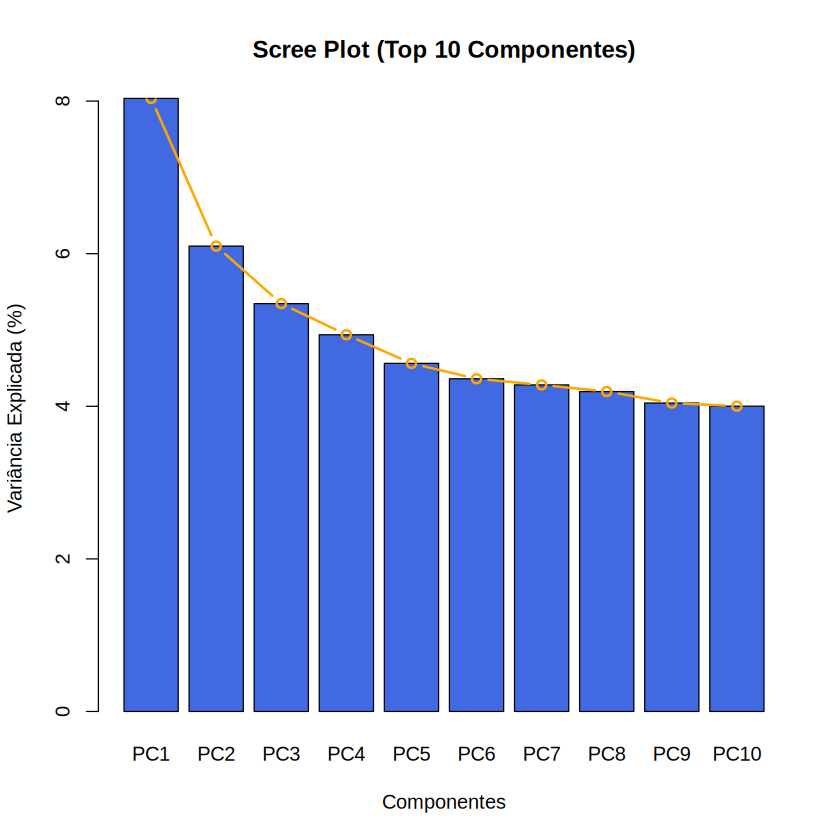

In [17]:
# Aplicar PCA com padronização (scale. = TRUE)
pca_res <- prcomp(X_encoded, center = TRUE, scale. = TRUE)

# Calcular variâncias e proporções
var_ind <- pca_res$sdev^2
var_explicada <- var_ind / sum(var_ind) * 100
var_acumulada <- cumsum(var_explicada)

# Tabela de Resumo das 10 primeiras Componentes
pca_summary <- data.frame(
  Componente = paste0("PC", 1:length(var_explicada)),
  Variancia_Explicada_Pct = var_explicada,
  Variancia_Acumulada_Pct = var_acumulada
)

print(head(pca_summary, 10))

# Scree Plot em R (Nativo)
barplot(var_explicada[1:10], names.arg = paste0("PC", 1:10),
        main = "Scree Plot (Top 10 Componentes)",
        col = "royalblue", ylab = "Variância Explicada (%)", xlab = "Componentes")
lines(1:10 * 1.2 - 0.5, var_explicada[1:10], type = "b", col = "orange", lwd = 2)

### Loadings (Pesos) e Relação com a IDADE

--- Variáveis Dominantes em PC1 ---
                                 RAÇABranca 
                                  0.4428342 
                            MUNICIPIOSantos 
                                  0.4390967 
                                  RAÇAParda 
                                  0.4030404 
                        LOCAL_MORTEHospital 
                                  0.3551832 
LOCAL_MORTEOutros estabelecimentos de saúde 
                                  0.2837611 
                ESCOLARIDADE12 anos ou mais 
                                  0.1874801 
                      MUNICIPIOPraia Grande 
                                  0.1546142 
                           MUNICIPIOGuarujá 
                                  0.1496453 
                     ESCOLARIDADE4 a 7 anos 
                                  0.1426761 
                     LOCAL_MORTEVia pública 
                                  0.1337599 

--- Variáveis Dominantes em PC2 ---
                           

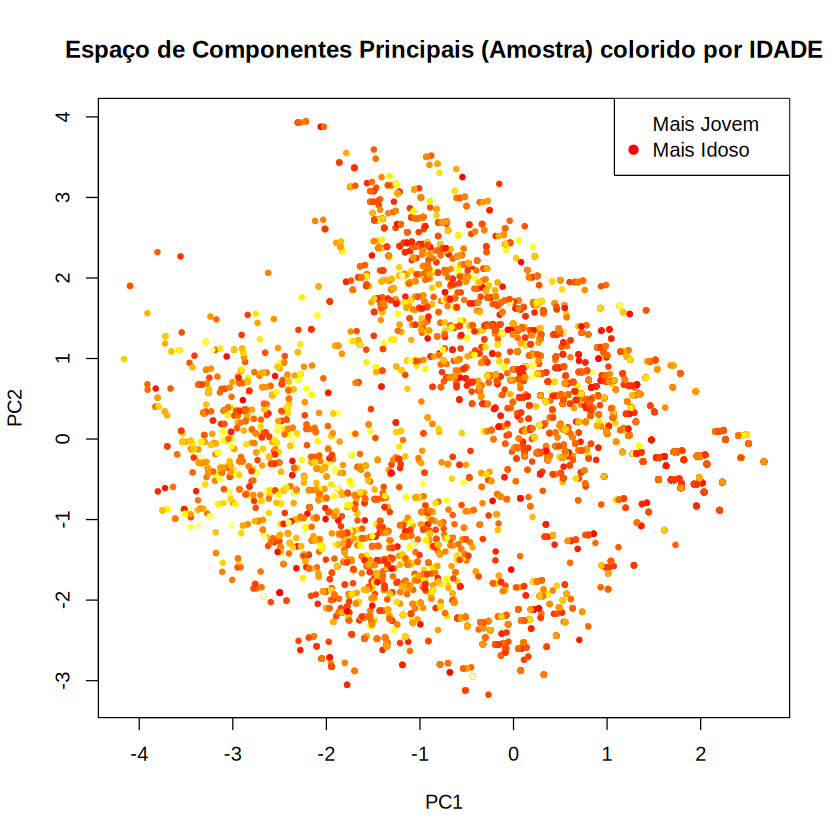

In [24]:
# Obter pesos (loadings) para PC1 e PC2
loadings <- pca_res$rotation

cat("--- Variáveis Dominantes em PC1 ---\n")
print(head(sort(abs(loadings[, 1]), decreasing = TRUE), 10))

cat("\n--- Variáveis Dominantes em PC2 ---\n")
print(head(sort(abs(loadings[, 2]), decreasing = TRUE), 10))

# Alinhar perfeitamente y_idade com as linhas mantidas na matriz X_encoded
manter_indices <- as.numeric(rownames(X_encoded))
y_idade_alinhada <- df_clean$IDADE[manter_indices]

# Verificar se os tamanhos são compatíveis agora
cat("\nLinhas na PCA:", nrow(pca_res$x), " | Linhas em IDADE alinhada:", length(y_idade_alinhada), "\n")

# Calcular correlação
cor_pc1_idade <- cor(pca_res$x[, 1], y_idade_alinhada, use = "complete.obs")
cor_pc2_idade <- cor(pca_res$x[, 2], y_idade_alinhada, use = "complete.obs")

cat("\nCorrelação de PC1 com IDADE:", cor_pc1_idade, "\n")
cat("Correlação de PC2 com IDADE:", cor_pc2_idade, "\n")

# Plotar gráfico de dispersão PC1 vs PC2 colorido pela IDADE usando amostragem para rapidez
set.seed(42)
amostra <- sample(1:nrow(pca_res$x), min(10000, nrow(pca_res$x)))

# Definir paleta de cores para Idade
cores <- rev(heat.colors(100))
idade_cols <- cores[as.numeric(cut(y_idade_alinhada[amostra], breaks = 100))]

plot(pca_res$x[amostra, 1], pca_res$x[amostra, 2], col = idade_cols,
     xlab = "PC1", ylab = "PC2", main = "Espaço de Componentes Principais (Amostra) colorido por IDADE",
     pch = 19, cex = 0.6)
legend("topright", legend = c("Mais Jovem", "Mais Idoso"), col = c(cores[1], cores[100]), pch = 19)